In [29]:
# Importing libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score ,confusion_matrix, classification_report 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


print("Libraries imported successfully ")

Libraries imported successfully 


In [30]:
df= pd.read_csv (r"C:\Users\taman\Downloads\CDS project files.csv\Predict_Blood_Donations_Data.csv")

In [31]:
df.head()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
0,619,2,50,12500,98,1
1,664,0,13,3250,28,1
2,441,1,16,4000,35,1
3,160,2,20,5000,45,1
4,358,1,24,6000,77,0


In [32]:
df.shape

(576, 6)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 576 entries, 0 to 575
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Unnamed: 0                   576 non-null    int64
 1   Months since Last Donation   576 non-null    int64
 2   Number of Donations          576 non-null    int64
 3   Total Volume Donated (c.c.)  576 non-null    int64
 4   Months since First Donation  576 non-null    int64
 5   Made Donation in March 2007  576 non-null    int64
dtypes: int64(6)
memory usage: 27.1 KB


In [34]:
df.isnull().sum()

Unnamed: 0                     0
Months since Last Donation     0
Number of Donations            0
Total Volume Donated (c.c.)    0
Months since First Donation    0
Made Donation in March 2007    0
dtype: int64

In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
df["Made Donation in March 2007"].value_counts()

Made Donation in March 2007
0    438
1    138
Name: count, dtype: int64

In [37]:
df["Made Donation in March 2007"].value_counts(normalize = True )*100

Made Donation in March 2007
0    76.041667
1    23.958333
Name: proportion, dtype: float64

In [38]:
df.describe()

,Unnamed: 0,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
count,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000
mean,374.034722,9.439236,5.427083,1356.770833,34.050347,0.239583
std,216.947773,8.175454,5.740010,1435.002556,24.227672,0.427200
min,0.000000,0.000000,1.000000,250.000000,2.000000,0.000000
25%,183.750000,2.000000,2.000000,500.000000,16.000000,0.000000
50%,375.500000,7.000000,4.000000,1000.000000,28.000000,0.000000
75%,562.500000,14.000000,7.000000,1750.000000,49.250000,0.000000
max,747.000000,74.000000,50.000000,12500.000000,98.000000,1.000000


##  Exploratory Data Analysis (EDA)

In [39]:
df_analysis =df.drop(columns=["Unnamed: 0"])
df_analysis.duplicated().sum()

np.int64(153)

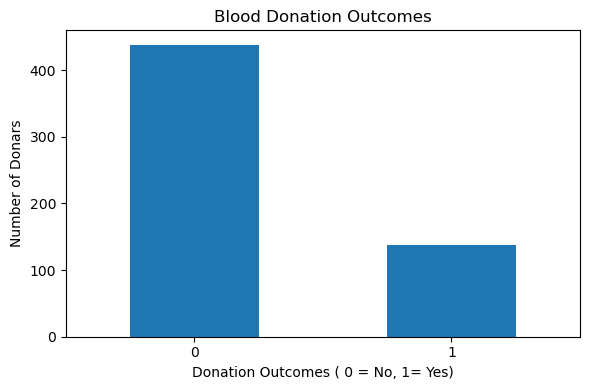

In [40]:
import matplotlib.pyplot as plt

df["Made Donation in March 2007"].value_counts().sort_index().plot(
    kind="bar",
    figsize =(6,4),
    title = "Blood Donation Outcomes"
)

plt.xlabel("Donation Outcomes ( 0 = No, 1= Yes)")
plt.ylabel("Number of Donars")
plt.xticks(rotation =0)
plt.tight_layout()
plt.show()


In [41]:
df_analysis.describe()

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation,Made Donation in March 2007
count,576.000000,576.000000,576.000000,576.000000,576.000000
mean,9.439236,5.427083,1356.770833,34.050347,0.239583
std,8.175454,5.740010,1435.002556,24.227672,0.427200
min,0.000000,1.000000,250.000000,2.000000,0.000000
25%,2.000000,2.000000,500.000000,16.000000,0.000000
50%,7.000000,4.000000,1000.000000,28.000000,0.000000
75%,14.000000,7.000000,1750.000000,49.250000,0.000000
max,74.000000,50.000000,12500.000000,98.000000,1.000000


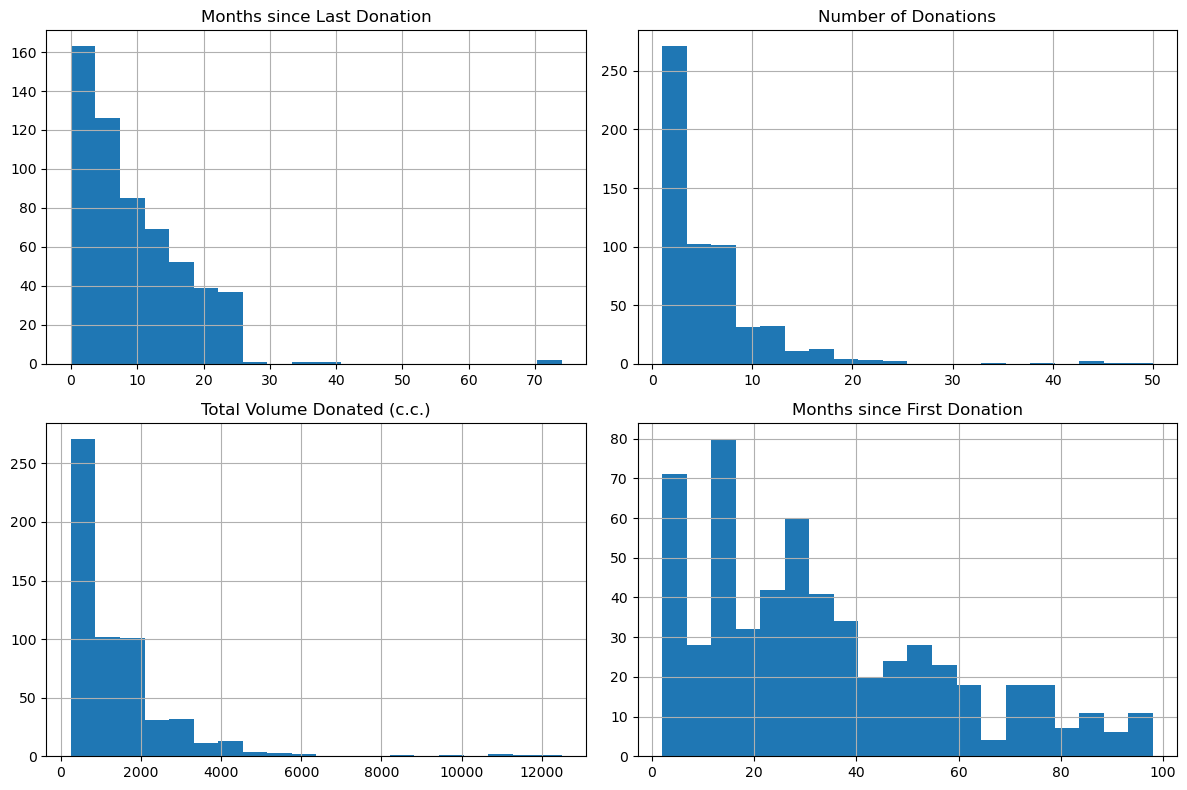

In [42]:
df_analysis.drop(
    columns=["Made Donation in March 2007"]
).hist(figsize=(12,8),
       bins=20)

plt.tight_layout()
plt.show()

In [43]:
target ="Made Donation in March 2007"
df_analysis.groupby(target).mean().round(2)

,Months since Last Donation,Number of Donations,Total Volume Donated (c.c.),Months since First Donation
Made Donation in March 2007,,,,
0,10.64,4.72,1179.22,34.32
1,5.64,7.68,1920.29,33.20


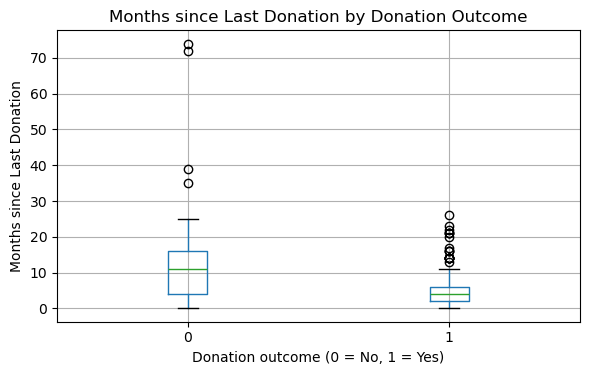

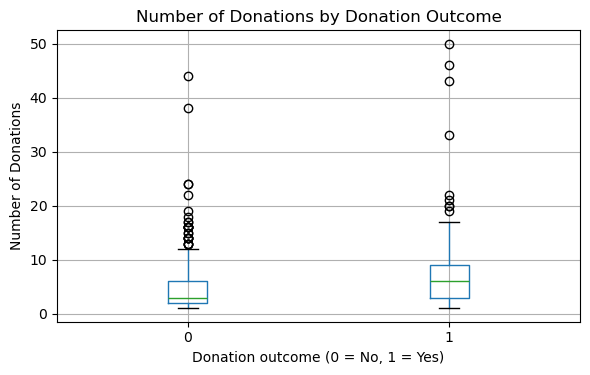

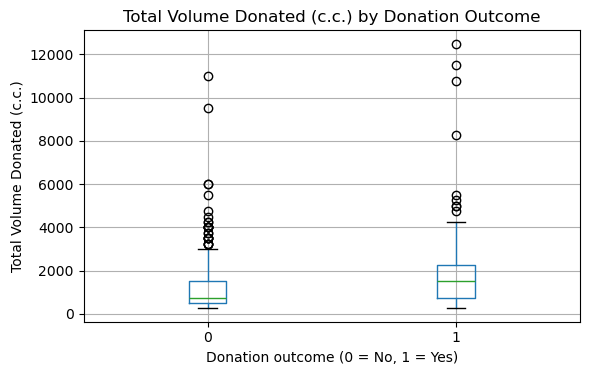

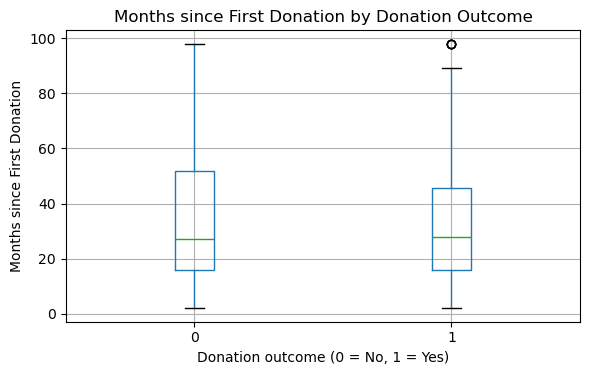

In [44]:
import matplotlib.pyplot as plt

features = [
    "Months since Last Donation",
    "Number of Donations",
    "Total Volume Donated (c.c.)",
    "Months since First Donation"
]

for feature in features:
    df_analysis.boxplot(
        column=feature,
        by=target,
        figsize=(6, 4)
    )

    plt.title(feature + " by Donation Outcome")
    plt.suptitle("")
    plt.xlabel("Donation outcome (0 = No, 1 = Yes)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

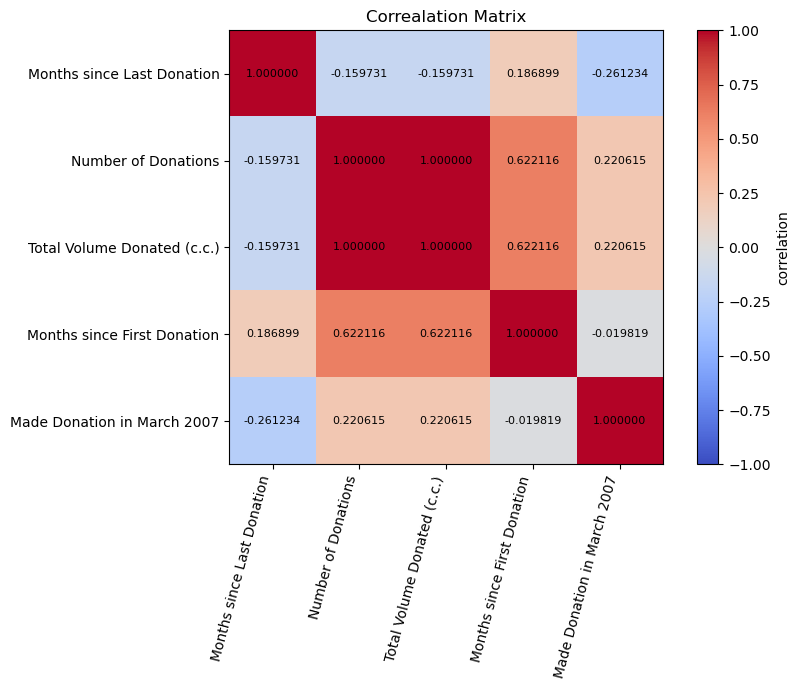

In [45]:
correlation = df_analysis.corr()

plt.figure(figsize= (9,7))

plt.imshow(correlation , cmap="coolwarm", vmin=-1,vmax=1)
plt.colorbar(label= "correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation =75,
    ha="right"
)


plt.yticks(
     range(len(correlation.columns)),
    correlation.columns
)

for i in range (len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,i,
            f"{correlation.iloc[i,j]:2f}" ,
            ha= "center",
            va= "center",
            fontsize =8
        )
plt.title("Correalation Matrix")
plt.tight_layout()
plt.show()


 ## data preparation for machine learning
 #### Step 1: Separate the features and target

In [46]:
df_model = df.drop(columns =["Unnamed: 0"]).copy()

x= df_model.drop(columns=["Made Donation in March 2007"])
y= df_model["Made Donation in March 2007"]

print("Features shape :",x.shape)
print ("Target shape :",y.shape )

Features shape : (576, 4)
Target shape : (576,)


#### Step 2: Split the dataset

In [47]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size =0.2,
    random_state =42,
    stratify =y     
)

print("x_train:",x_train.shape)
print("x_test:",x_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

x_train: (460, 4)
x_test: (116, 4)
y_train: (460,)
y_test: (116,)


 #### Step 3: Check the class proportions after splitting

In [48]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training target distribution:
Made Donation in March 2007
0    0.761
1    0.239
Name: proportion, dtype: float64

Testing target distribution:
Made Donation in March 2007
0    0.759
1    0.241
Name: proportion, dtype: float64


### Next step: first baseline model

In [49]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score ,confusion_matrix, classification_report 

baseline = DummyClassifier(strategy ="most_frequent")
baseline.fit(x_train,y_train)
y_pred_baseline = baseline.predict(x_test)

print("Baseline Accuracy :",accuracy_score(y_test,y_pred_baseline))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_baseline))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
    
))

Baseline Accuracy : 0.7586206896551724

Confusion Matrix:
[[88  0]
 [28  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86        88
           1       0.00      0.00      0.00        28

    accuracy                           0.76       116
   macro avg       0.38      0.50      0.43       116
weighted avg       0.58      0.76      0.65       116



### Next step: Logistic Regression

In [50]:


log_model = Pipeline([
    ("scaler",StandardScaler()),
    ("classifier",LogisticRegression(random_state=42))
])

log_model.fit(x_train,y_train)

y_pred_log = log_model.predict(x_test)
print("Logistic Regression Accuracy:",
     accuracy_score(y_test,y_pred_log))

print("\nConfusion Matrix :")
print(confusion_matrix(y_test,y_pred_log,labels=[0,1]))

print("\n Classification Report :")
print(classification_report(
    y_test,
    y_pred_log,
    labels=[0,1],
    target_names=["Did not donate","Donated"],
    zero_division=0
))


Logistic Regression Accuracy: 0.7758620689655172

Confusion Matrix :
[[85  3]
 [23  5]]

 Classification Report :
                precision    recall  f1-score   support

Did not donate       0.79      0.97      0.87        88
       Donated       0.62      0.18      0.28        28

      accuracy                           0.78       116
     macro avg       0.71      0.57      0.57       116
  weighted avg       0.75      0.78      0.73       116



### Next model: Decision Tree Classifier

In [51]:
 
tree_model = DecisionTreeClassifier(
    max_depth =3,
    random_state =42
)
tree_model.fit(x_train,y_train)
y_pred_tree =tree_model.predict(x_test)
print("Decision Tree Accuracy:",
      accuracy_score(y_test,y_pred_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_tree))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    zero_division=0
))

Decision Tree Accuracy: 0.7327586206896551

Confusion Matrix:
[[77 11]
 [20  8]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.88      0.83        88
           1       0.42      0.29      0.34        28

    accuracy                           0.73       116
   macro avg       0.61      0.58      0.59       116
weighted avg       0.70      0.73      0.71       116



### Next step :Random Forest

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

rf_model= RandomForestClassifier(
    n_estimators= 200,
    random_state=42
)
rf_model.fit(x_train,y_train)

y_pred_rf = rf_model.predict(x_test)

print("Random Forest Accuracy :",accuracy_score(y_test,y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred_rf))

print("\nClassification Report :")
print(classification_report(y_test,y_pred_rf,zero_division=0))

Random Forest Accuracy : 0.7155172413793104

Confusion Matrix:
[[74 14]
 [19  9]]

Classification Report :
              precision    recall  f1-score   support

           0       0.80      0.84      0.82        88
           1       0.39      0.32      0.35        28

    accuracy                           0.72       116
   macro avg       0.59      0.58      0.59       116
weighted avg       0.70      0.72      0.71       116



 ### compare models with 5-fold cross-validation

In [53]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring="f1"
    )
    print(f"{name}: Mean F1 = {scores.mean():.3f}, SD = {scores.std():.3f}")

Logistic Regression: Mean F1 = 0.165, SD = 0.083
Decision Tree: Mean F1 = 0.452, SD = 0.058
Random Forest: Mean F1 = 0.410, SD = 0.092


### Model Comparison and Selection:

In [54]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Test Accuracy": [0.759, 0.776, 0.733, 0.716],
    "Donor Precision (Class 1)": [0.00, 0.62, 0.42, 0.39],
    "Donor Recall (Class 1)": [0.00, 0.18, 0.29, 0.32],
    "Donor F1 (Test)": [0.00, 0.28, 0.34, 0.35],
    "CV Mean F1": [None, 0.165, 0.452, 0.410],
    "CV F1 SD": [None, 0.083, 0.058, 0.092]
})

comparison

,Model,Test Accuracy,Donor Precision (Class 1),Donor Recall (Class 1),Donor F1 (Test),CV Mean F1,CV F1 SD
0,Dummy Classifier,0.759,0.00,0.00,0.00,NaN,NaN
1,Logistic Regression,0.776,0.62,0.18,0.28,0.165,0.083
2,Decision Tree,0.733,0.42,0.29,0.34,0.452,0.058
3,Random Forest,0.716,0.39,0.32,0.35,0.410,0.092


## Challenges & Techniques

### Challenges

One of the main challenges in this project was the **class imbalance** in the target variable. The dataset contained more records of people who did not donate blood than people who donated blood. Therefore, accuracy alone was not sufficient to evaluate the model performance.

Another challenge was identifying a suitable classification algorithm that could effectively predict blood donation outcomes. Different machine learning algorithms were therefore tested and compared.

### Techniques Used

The following techniques were used to build and evaluate the blood donation prediction models:

* **Stratified Train-Test Split:** The dataset was divided into training and testing sets using stratification so that the proportion of both target classes was maintained in the training and testing datasets.

* **Multiple Classification Algorithms:** Different classification models were implemented and compared:

  * Dummy Classifier
  * Logistic Regression
  * Decision Tree
  * Random Forest

* **Performance Evaluation:** Since the target classes were imbalanced, multiple evaluation metrics were used instead of relying only on accuracy:

  * Precision
  * Recall
  * F1-score
  * Confusion Matrix

* **Baseline Comparison:** A Dummy Classifier was used as a baseline model. The other machine learning models were compared against this baseline to determine whether they provided useful predictive performance.

* **Model Comparison:** The performance of Logistic Regression, Decision Tree, and Random Forest was compared using the evaluation metrics and cross-validation F1-scores to understand their effectiveness for predicting blood donation.


## Conclusion

This project focused on predicting whether a person would donate blood using historical blood donation data. The dataset was explored and analyzed to understand its structure, features, and target variable before developing the machine learning models.

The Blood Donation Prediction project analyzed donor data and developed multiple classification models. Dummy Classifier, Logistic Regression, Decision Tree, and Random Forest were compared.

Logistic Regression achieved the highest test accuracy of 77.59%, while the Decision Tree achieved the highest cross-validation mean F1-score of 0.452. Random Forest achieved a donor-class F1-score of 0.35 on the test set.

The results show that accuracy alone is not sufficient for this imbalanced dataset, so precision, recall, F1-score, and cross-validation were also considered.

This project provided practical experience in applying classification techniques to a real-world prediction problem and showed the importance of selecting appropriate evaluation metrics when working with imbalanced datasets.
